# Figure 3: Time Series - HSSW Arrival

## Import Packages

In [1]:
import pandas as pd
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, zoomed_inset_axes
import matplotlib.ticker as mticker
from matplotlib import path
from matplotlib.colors import TwoSlopeNorm
import matplotlib.cm as cm
from matplotlib.patches import Polygon
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import matplotlib.lines as mlines
import datetime

import xarray as xr
from netCDF4 import Dataset
from xgcm import Grid
import cmaps
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os
import glob

import rioxarray

from dask.diagnostics import ProgressBar

from scipy.ndimage import gaussian_filter1d

from pyproj import Transformer

import seawater as sw
import gsw

import calendar

import pickle

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/sitecustomize.py:72: UserWarning: The seawater library is deprecated! Please use gsw instead.
  mod = _real_import(name, globals, locals, fromlist, level)


## Import Data

In [2]:
ROOT = '/g/data/gv90/ad6790/amery-amisor'
os.chdir(f'{ROOT}/notebooks')

from fun_filtering import lowpass_filter

df = pd.read_parquet(f'{ROOT}/data/proc/04_filtered.parquet')

## Define Resuable Functions

In [3]:
def composite_seasonal_cycle(df, borehole, cat):
    # Create a mask to filter the specified borehole and cat
    sub = df[(df["borehole"] == borehole) & (df["cat"] == cat)].copy()
    sub = sub.sort_values("time")
    
    # Extract day of year from the time column
    sub["doy"] = sub["time"].dt.dayofyear + sub["time"].dt.hour / 24 + sub["time"].dt.minute / 1440
    
    # Round to nearest half-hour (1/48 of a day) since each MicroCAT records data with a half-hour interval, although due to time drift
    # the equivalent timestamp on different years may not be exactly the same time to the second
    sub["doy_bin"] = (sub["doy"] * 48).round() / 48

    # Define a dictionary to store the data and associated variables
    out = {"data": sub}

    # Create a pad either side which is twice the length of the cutoff_period
    n_pad = int((cutoff_period * 2) / sampling_interval)

    for key, col in [("temp", "conservative_temperature"), ("sal", "absolute_salinity")]:
        # Group temp or salinity by day of year
        grouped = sub.groupby("doy_bin")[col]

        # Calculate stats on the equivalent timestamp between different years
        stats = [("mean", grouped.mean()), ("std", grouped.std()), ("median", grouped.median()), ("q1", grouped.quantile(0.25)), ("q3", grouped.quantile(0.75))]

        for stat_name, series in stats:
            values = series.values
    
            # Since our lowpass filter uses .sosfiltfilt(), it applies the filter forwards and backwards through time
            # However, the data at the start and end of the year does not have data before and after it, respectively
            # We need to pad the data either side to treat the multi-year median as continuous
            # This is reasonable given that the seasonal data is naturally cyclic
            padded = np.concatenate([values[-n_pad:], values, values[:n_pad]])
    
            # Apply the filter function to the padded stat values
            filtered = lowpass_filter(padded, cutoff_period=cutoff_period, sampling_interval=sampling_interval, max_gap_hours=max_gap_hours)

            # Remove the padded data from the filtered data and save in the dictionary
            out[f"{key}_{stat_name}"] = filtered[n_pad:-n_pad]

        # Retain the DOY index to be able to plot the smoothed average values
        out["doy_index"] = series.index

    return out

## HSSW Onset Calculations

### Define the Determined HSSW Onset DOYs

In [4]:
# Onset day-of-year for the arrival of HSSW at each borehole, by year
HSSW_ONSET = {
    "AM01": {2002: 156, 2003: 211, 2004: 183, 2005: 176, 2006: 217, 2007: 179},
    "AM02": {2001: 238, 2003: 245, 2004: 213, 2005: 222, 2006: 252},
    "AM06": {2010: 239, 2011: 211, 2012: 196},
    "AM03": {2006: 263, 2007: 222, 2008: 194, 2009: 196, 2010: 259},
}

### Define Magnitudes of Change and Duration

In [5]:
# Bottom two MicroCATs at each borehole (borehole, cat)
boreholes = [
    ("AM01", "1970"), ("AM01", "1971"),
    ("AM02", "1624"), ("AM02", "1174"),
    ("AM06", "7324"), ("AM06", "7323"),
    ("AM03", "4054"), ("AM03", "3883"),
]

# Restrict search for temp arrival to a DOY window
SEARCH_DOY = (150, 300)
# Length of the before/after windows used for the raw means (days)
WINDOW_DAYS = 5
# Gap either side of the arrival excluded from those windows, so the transition itself isn't averaged in (days)
BUFFER_DAYS = 5
# How far after the arrival to look for the salinity maximum (days)
SAL_SEARCH_DAYS = 150

rows = []

# Iterate the defined boreholes and microcats
for bh, cat in boreholes:
    # Extract the CTD data for this MicroCAT
    microcat_data = df[(df["borehole"] == bh) & (df["cat"] == cat)].sort_values("time")

    # Iterate years contained in the microcat data
    for year in sorted(microcat_data["time"].dt.year.unique()):
        if year not in HSSW_ONSET[bh]:
            continue
        
        # Extract the CTD data for this year
        year_data = microcat_data[microcat_data["time"].dt.year == year]
        # Convert each timestep to a DOY value
        time_in_days = (year_data["time"] - year_data["time"].iloc[0]).dt.total_seconds().values / 86400
        # Extract the DOY values of each timestep
        doy = year_data["time"].dt.dayofyear.values

        # --------------- ARRIVAL: ANNUAL MINIMUM TEMP (FOR COMPARISON) ---------------
        temp = year_data["conservative_temperature_smooth_30d"]
        
        # Restrict to the DOY search window and valid temperature values
        arrival_search = ((doy >= SEARCH_DOY[0]) & (doy <= SEARCH_DOY[1]) & temp.notna().to_numpy())
        if not arrival_search.any():
            continue
        
        # Find the index of the minimum smoothed temperature in the search window
        temp_values = temp.to_numpy()
        temp_min_index = np.argmin(np.where(arrival_search, temp_values, np.inf))
        
        # Arrival is the first observation after the annual temperature minimum
        if temp_min_index + 1 >= len(year_data):
            continue
        
        temp_min_time = year_data["time"].iloc[temp_min_index + 1]

        # --------------- ARRIVAL: MANUALLY SELECTED ---------------
        temp_signal_time = (pd.Timestamp(year=int(year), month=1, day=1) + pd.Timedelta(days=HSSW_ONSET[bh][year] - 1))

        # --------------- SALINITY PEAK ---------------
        # Restrict the smoothed data to an arbitrarily chosen time period following the signal to find the max salinity value
        smooth_data_after = microcat_data[(microcat_data["time"] >= temp_signal_time) & (microcat_data["time"] <= temp_signal_time + pd.Timedelta(days=SAL_SEARCH_DAYS))]
        if smooth_data_after["absolute_salinity_smooth_30d"].notna().sum() > 0:
            # Find the timestep of the max salinity value observed in the arbitrarily chosen time period following the signal
            max_salt_time = smooth_data_after.loc[smooth_data_after["absolute_salinity_smooth_30d"].idxmax(), "time"]
        else:
            max_salt_time = temp_signal_time + pd.Timedelta(days=100)
            
        # --------------- DURATION ---------------
        # Calculate the duration of the signal from when temperature is first observed increasing to when the salinity reaches its peak
        duration = (max_salt_time - temp_signal_time).total_seconds() / 86400

        # To find the magnitude of change, restrict the search for min and max to 10 days (arbitrary) before the signal and the duration after the signal, respectively
        microcat_data_before = microcat_data[(microcat_data["time"] >= temp_signal_time - pd.Timedelta(days=10)) & (microcat_data["time"] < temp_signal_time)]
        microcat_data_after = microcat_data[(microcat_data["time"] >= temp_signal_time) & (microcat_data["time"] <= max_salt_time)]
        if microcat_data_before.empty or microcat_data_after.empty:
            continue

        # --------------- MAGNITUDES OF CHANGE ---------------
        temp_signal_magnitude = microcat_data_after["conservative_temperature_smooth_30d"].max() - microcat_data_before["conservative_temperature_smooth_30d"].min()
        salt_signal_magnitude = microcat_data_after["absolute_salinity_smooth_30d"].max() - microcat_data_before["absolute_salinity_smooth_30d"].min()

        if smooth_data_after["absolute_salinity_smooth_30d"].notna().sum() == 0:
            max_salt_time = np.nan
            
        rows.append(dict(
            borehole=bh, cat=cat, year=year,
            min_temp_doy=temp_min_time.dayofyear,
            arrival_doy=temp_signal_time.dayofyear,
            max_salt_time=max_salt_time if pd.notna(max_salt_time) else np.nan,
            salt_peak_doy = max_salt_time.dayofyear if pd.notna(max_salt_time) else np.nan,
            hand_picked_doy=HSSW_ONSET.get(bh, {}).get(year),
            dT=temp_signal_magnitude,
            dS=salt_signal_magnitude,
            duration_days=duration,
        ))

hssw = pd.DataFrame(rows)
print(hssw.round(3).to_string(index=False))

borehole  cat  year  min_temp_doy  arrival_doy       max_salt_time  salt_peak_doy  hand_picked_doy    dT    dS  duration_days
    AM01 1970  2002           157          156 2002-08-09 23:30:01          221.0              156 0.213 0.076         65.979
    AM01 1970  2003           211          211 2003-10-19 13:30:01          292.0              211 0.236 0.055         81.563
    AM01 1970  2004           155          183 2004-10-21 10:57:56          295.0              183 0.250 0.066        112.457
    AM01 1970  2005           176          176 2005-09-09 11:58:12          252.0              176 0.209 0.069         76.499
    AM01 1970  2006           153          217 2006-09-24 15:25:30          267.0              217 0.187 0.052         50.643
    AM01 1970  2007           179          179 2007-08-28 06:27:58          240.0              179 0.168 0.053         61.269
    AM01 1971  2002           156          156 2002-10-10 11:00:01          283.0              156 0.143 0.098        

### Summarise HSSW Onset for Each Borehole and MicroCAT

In [6]:
results = pd.DataFrame(rows)

# --------------- SUMMARY PER BOREHOLE PER YEAR ---------------
borehole_summary = (hssw.groupby(["borehole", "year"]).agg(arrival_doy=("arrival_doy", "first"), salt_peak_time=("max_salt_time", "max")).reset_index())

borehole_summary["arrival_time"] = (pd.to_datetime(borehole_summary["year"].astype(str) + "-01-01") + pd.to_timedelta(borehole_summary["arrival_doy"] - 1, unit="D"))

borehole_summary["salt_peak_doy"] = (borehole_summary["salt_peak_time"].dt.dayofyear)

# Duration for each borehole in each year
borehole_summary["duration_days"] = (borehole_summary["salt_peak_time"] - borehole_summary["arrival_time"]).dt.total_seconds() / 86400

# --------------- AVERAGES PER MICROCAT ---------------
microcat_summary = (hssw.groupby(["borehole", "cat"]).agg(mean_dT=("dT", "mean"), mean_dS=("dS", "mean")).reset_index())

microcat_summary[["mean_dT", "mean_dS"]] = (microcat_summary[["mean_dT", "mean_dS"]].round(2))

print("Summary per borehole:")
print(borehole_summary.to_string(index=False))

print("\nAverage changes per MicroCAT:")
print(microcat_summary.to_string(index=False))

Summary per borehole:
borehole  year  arrival_doy      salt_peak_time arrival_time  salt_peak_doy  duration_days
    AM01  2002          156 2002-10-10 11:00:01   2002-06-05            283     127.458345
    AM01  2003          211 2003-11-21 11:00:01   2003-07-30            325     114.458345
    AM01  2004          183 2004-10-21 13:27:33   2004-07-01            295     112.560799
    AM01  2005          176 2005-11-01 20:27:29   2005-06-25            305     129.852419
    AM01  2006          217 2006-10-07 17:54:39   2006-08-05            280      63.746285
    AM01  2007          179 2007-08-28 06:27:58   2007-06-28            240      61.269421
    AM02  2001          238 2001-12-27 06:11:11   2001-08-26            361     123.257766
    AM02  2003          245 2004-01-11 02:29:56   2003-09-02             11     131.104120
    AM02  2004          213 2004-11-12 06:56:17   2004-07-31            317     104.289086
    AM02  2005          222 2005-10-10 11:26:37   2005-08-10        

## Define Constant and Common Variables

In [7]:
# Define global colour mapping for each year to ensure consistency across boreholes and MicroCATs
YEAR_COLOURS = {
    2001: "tab:blue",   2002: "tab:orange", 2003: "tab:green",
    2004: "tab:red",    2005: "tab:purple", 2006: "tab:brown",
    2007: "tab:pink",   2008: "tab:olive",  2009: "tab:cyan",
    2010: "darkblue",   2011: "crimson",    2012: "teal",
    2013: "goldenrod",
}

# Define a dictionary mapping each MicroCAT to it's pre-calculated average pressure
# Average pressure is the mean pressure on deployment
AVG_PRESSURES = {
    "1969": 441.1,    "1970": 581.6,   "1971": 743.4,
    "1623": 338.5,    "1624": 562.7,   "1174": 770.2,
    "4055": 661.4,    "4054": 872.2,   "3883": 1227.1,
    "1972": 550.4,    "1973": 693.0,   "1974": 814.7,
    "7327": 580.5,    "7326": 738.8,   "7322": 876.6,
    "7325": 551.4,    "7324": 680.8,   "7323": 790.3,
}

# Colours assigned to boreholes in month mode (when multiple boreholes are shown)
BOREHOLE_COLOURS = {
    "AM01": {"1969": "darkgreen", "1970": "forestgreen", "1971": "mediumseagreen"},
    "AM02": {"1623": "darkred", "1624": "red", "1174": "indianred"},
    "AM03": {"4055": "saddlebrown", "4054": "sandybrown", "3883": "peru"},
    "AM04": {"1972": "black", "1973": "grey", "1974": "darkgrey"},
    "AM05": {"7327": "indigo", "7326": "darkviolet", "7322": "mediumorchid"},
    "AM06": {"7325": "navy", "7324": "royalblue", "7323": "cornflowerblue"},
}

POSITION_INDEX = {"upper": 0, "middle": 1, "lower": 2}

# Define the limits of the y-axes for plots of temperature and salinity
ylim_temp = (-2.25, -1.85)
ylim_sal = (34.5, 34.75)

raw_kw = dict(lw=0.8, alpha=0.2, zorder=1)
bandlines_kw = dict(label="_", lw=0.4, zorder=2)
band_kw = dict(hatch=None, alpha=0.2, zorder=2)
smooth_kw = dict(lw=1.5, zorder=4)
avg_kw = dict(lw=1, zorder=3)
year_arrival_kwargs = dict(linestyle='-', lw=1)

FS_MAIN = 12     # panel titles, axis labels, instrument labels
FS_SMALL = 12    # tick labels, including the month letters

plt.rcParams.update({
    "font.size": FS_MAIN,
    "axes.titlesize": FS_MAIN,
    "axes.labelsize": FS_MAIN,
    "xtick.labelsize": FS_SMALL,
    "ytick.labelsize": FS_SMALL,
    "legend.fontsize": FS_SMALL,
})

## Filtering/Smoothing
### Define Parameters for Applying Filtering

Remove tidal and other short-term influences.

In [8]:
# Define the cutoff period for filtering in days (or hours)
cutoff_period_days = 10 # days
cutoff_period = cutoff_period_days*24 # hours
# cutoff_period = 48 # hours

# The sampling interval is 0.5 hours, given that each MicroCAT records observations every 30 minutes
sampling_interval=0.5

# Define a period of time in days for less than which we are comfortable interpolating for 
# Set this to 0 for no interpolation
# Ideally want no more than about 1/4 of the cutoff period
interpolate_days = 2.5 # days
max_gap_hours=interpolate_days*24 # hours
# max_gap_hours=12 # hours

## Figure 3: Smoothed Composite Time Series

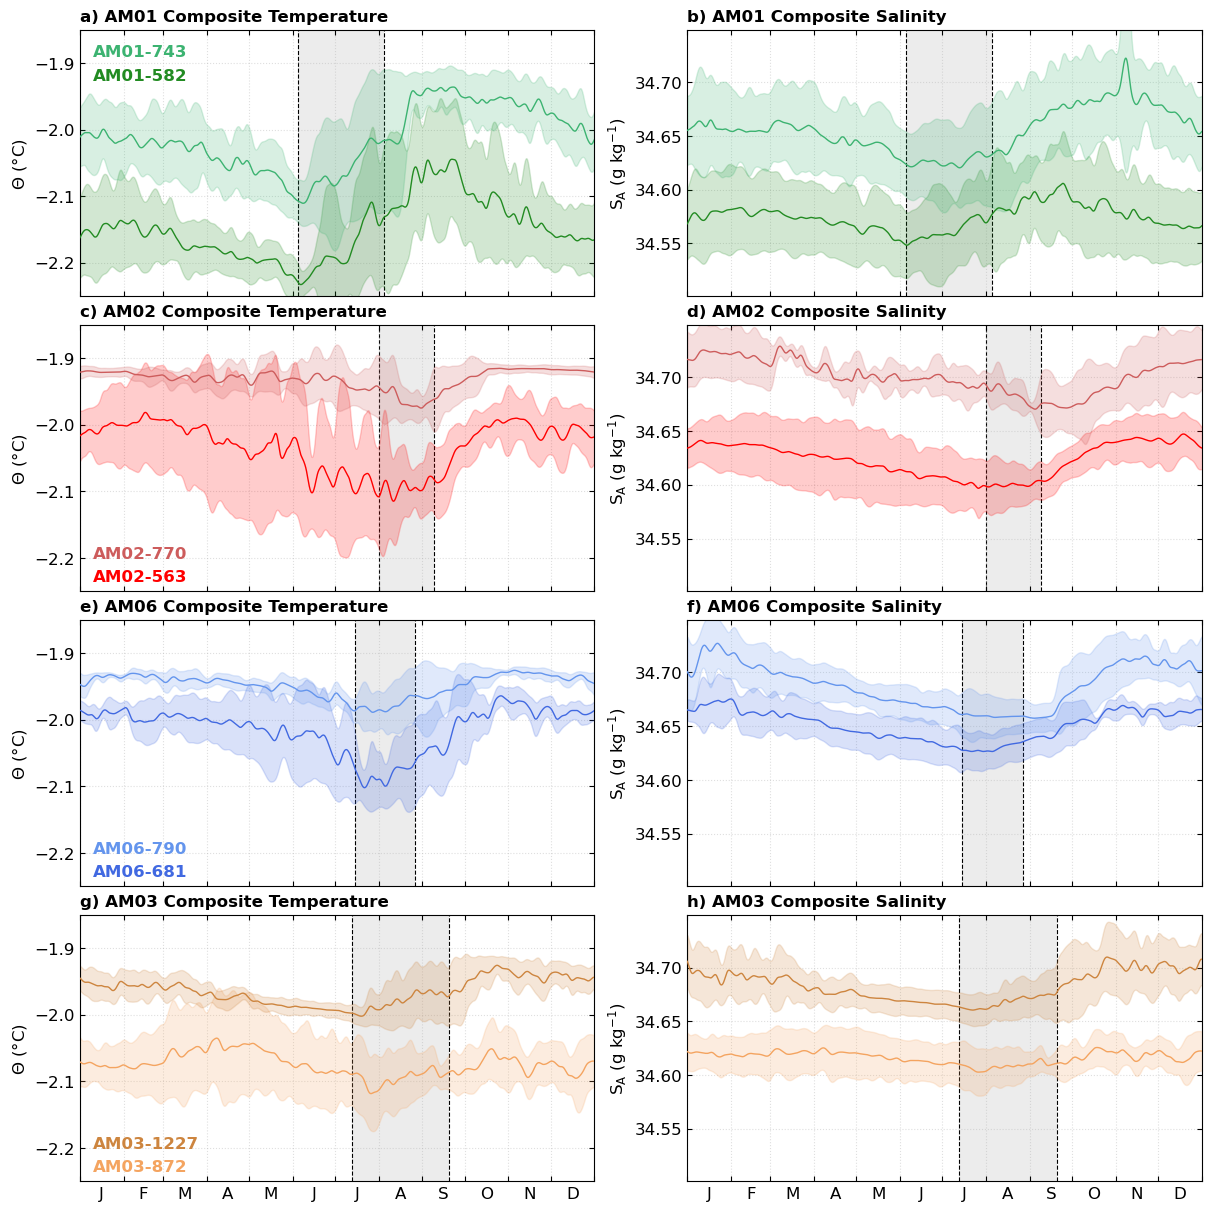

In [9]:
# Define the borehole, and associated MicroCATs at that borehole 
boreholes = [
    ("AM01", ["1970", "1971"]), 
    ("AM02", ["1624", "1174"]), 
    ("AM06", ["7324", "7323"]), 
    ("AM03", ["4054", "3883"])
]

mean_no_median = True

rows = len(boreholes)

fig, axes = plt.subplots(rows, 2, sharex=True, figsize=(12, 3*rows), layout='constrained', squeeze=False)

# Panel labels run left to right, then down
panel_labels = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h']
panel_count = 0

for i, (bh, cat_list) in enumerate(boreholes):
    axT, axS = axes[i, 0], axes[i, 1]

    cat_count = 0
    
    for cat in cat_list:
        r = composite_seasonal_cycle(df, bh, cat)
        sub = r["data"]
        label = f"{bh}-{AVG_PRESSURES[cat]:.0f}"
    
        # Extract day of year and year from the time column
        sub["year"] = sub["time"].dt.year

        # average_colour = "black"
        average_colour = BOREHOLE_COLOURS[bh][cat]
        if mean_no_median:
            axT.fill_between(r["doy_index"], r["temp_mean"] - r["temp_std"], r["temp_mean"] + r["temp_std"], color=average_colour, facecolor=average_colour, edgecolor=average_colour, label=r"$\pm 1\sigma$", **band_kw)
            axS.fill_between(r["doy_index"], r["sal_mean"] - r["sal_std"], r["sal_mean"] + r["sal_std"], color=average_colour, facecolor=average_colour, edgecolor=average_colour, label=r"$\pm 1\sigma$", **band_kw)
    
            axT.plot(r["doy_index"], r["temp_mean"], label="Mean", color=average_colour, **avg_kw)
            axS.plot(r["doy_index"], r["sal_mean"], label="Mean", color=average_colour, **avg_kw)
        else:
            axT.fill_between(r["doy_index"], r["temp_q1"], r["temp_q3"], color=average_colour, label="IQR", **band_kw)
            axS.fill_between(r["doy_index"], r["sal_q1"], r["sal_q3"], color=average_colour, label="IQR", **band_kw)
    
            axT.plot(r["doy_index"], r["temp_median"], label="Median", color=average_colour, **avg_kw)
            axS.plot(r["doy_index"], r["sal_median"], label="Median", color=average_colour, **avg_kw)
    
        # Retrieve the position of the iterated MicroCAT in the water column
        position = sub["water_column_position"].iloc[0]

        if bh == "AM01":
            axT.text(10, -1.93 + 0.035 * cat_count, label, color=BOREHOLE_COLOURS[bh][cat], fontweight='bold', va="bottom", ha="left", zorder=2)
        else:
            axT.text(10, -2.24 + 0.035 * cat_count, label, color=BOREHOLE_COLOURS[bh][cat], fontweight='bold', va="bottom", ha="left", zorder=2)
        cat_count += 1

    # Shade the range of observed HSSW onset dates at this borehole
    onset_doys = list(HSSW_ONSET[bh].values())
    axT.axvspan(min(onset_doys), max(onset_doys), color="grey", alpha=0.15, lw=0, zorder=-2)
    axS.axvspan(min(onset_doys), max(onset_doys), color="grey", alpha=0.15, lw=0, zorder=-2)
    # Dashed black lines on the edges of the onset band
    axT.axvline(min(onset_doys), color="black", ls="--", lw=0.8, zorder=-1)
    axT.axvline(max(onset_doys), color="black", ls="--", lw=0.8, zorder=-1)
    axS.axvline(min(onset_doys), color="black", ls="--", lw=0.8, zorder=-1)
    axS.axvline(max(onset_doys), color="black", ls="--", lw=0.8, zorder=-1)

    # Set the axis limits
    axT.set_ylim(ylim_temp[0], ylim_temp[1])
    axS.set_ylim(ylim_sal[0] + 0.001, ylim_sal[1] - 0.001)

    # Label the y-axis
    axT.set_ylabel(r"$\Theta$ (°C)")
    axS.set_ylabel(r"$\mathrm{S_{A} \ (g \ kg^{-1}})$")
    
    for ax in (axT, axS):
        ax.tick_params(axis="both", direction="in", top=True, right=True)
        ax.grid(True, linestyle=":", alpha=0.4)

    axT.yaxis.set_major_locator(mticker.MultipleLocator(0.1))
    axS.yaxis.set_major_locator(mticker.MultipleLocator(0.05))

    axT.set_title(f'{panel_labels[panel_count]}) {bh} Composite Temperature', loc='left', fontweight="bold")
    panel_count += 1
    axS.set_title(f'{panel_labels[panel_count]}) {bh} Composite Salinity', loc='left', fontweight="bold")
    panel_count += 1

# Month-start DOYs for a non-leap reference year, plus the right edge
starts = [datetime.date(2001, m, 1).timetuple().tm_yday for m in range(1, 13)] + [366]

centres = [(starts[i] + starts[i+1]) / 2 for i in range(12)]
labels = [datetime.date(2001, m, 1).strftime("%b")[0] for m in range(1, 13)]

for c in (0, 1):
    ax = axes[-1, c]
    ax.set_xticks(starts, minor=False)
    ax.set_xticklabels([""] * len(starts))
    ax.set_xticks(centres, minor=True)
    ax.set_xticklabels(labels, minor=True)
    ax.set_xlim(1, 366)

for ax in axes.flat:
    ax.tick_params(axis="x", which="minor", length=0)

fig.canvas.draw()
# fig.savefig('/g/data/gv90/ad6790/amery-amisor/notebooks/figures/ObsTimeSeriesHSSW.png', format='png', dpi=600)
plt.show()

## Figure SI: Smoothed Raw Time Series

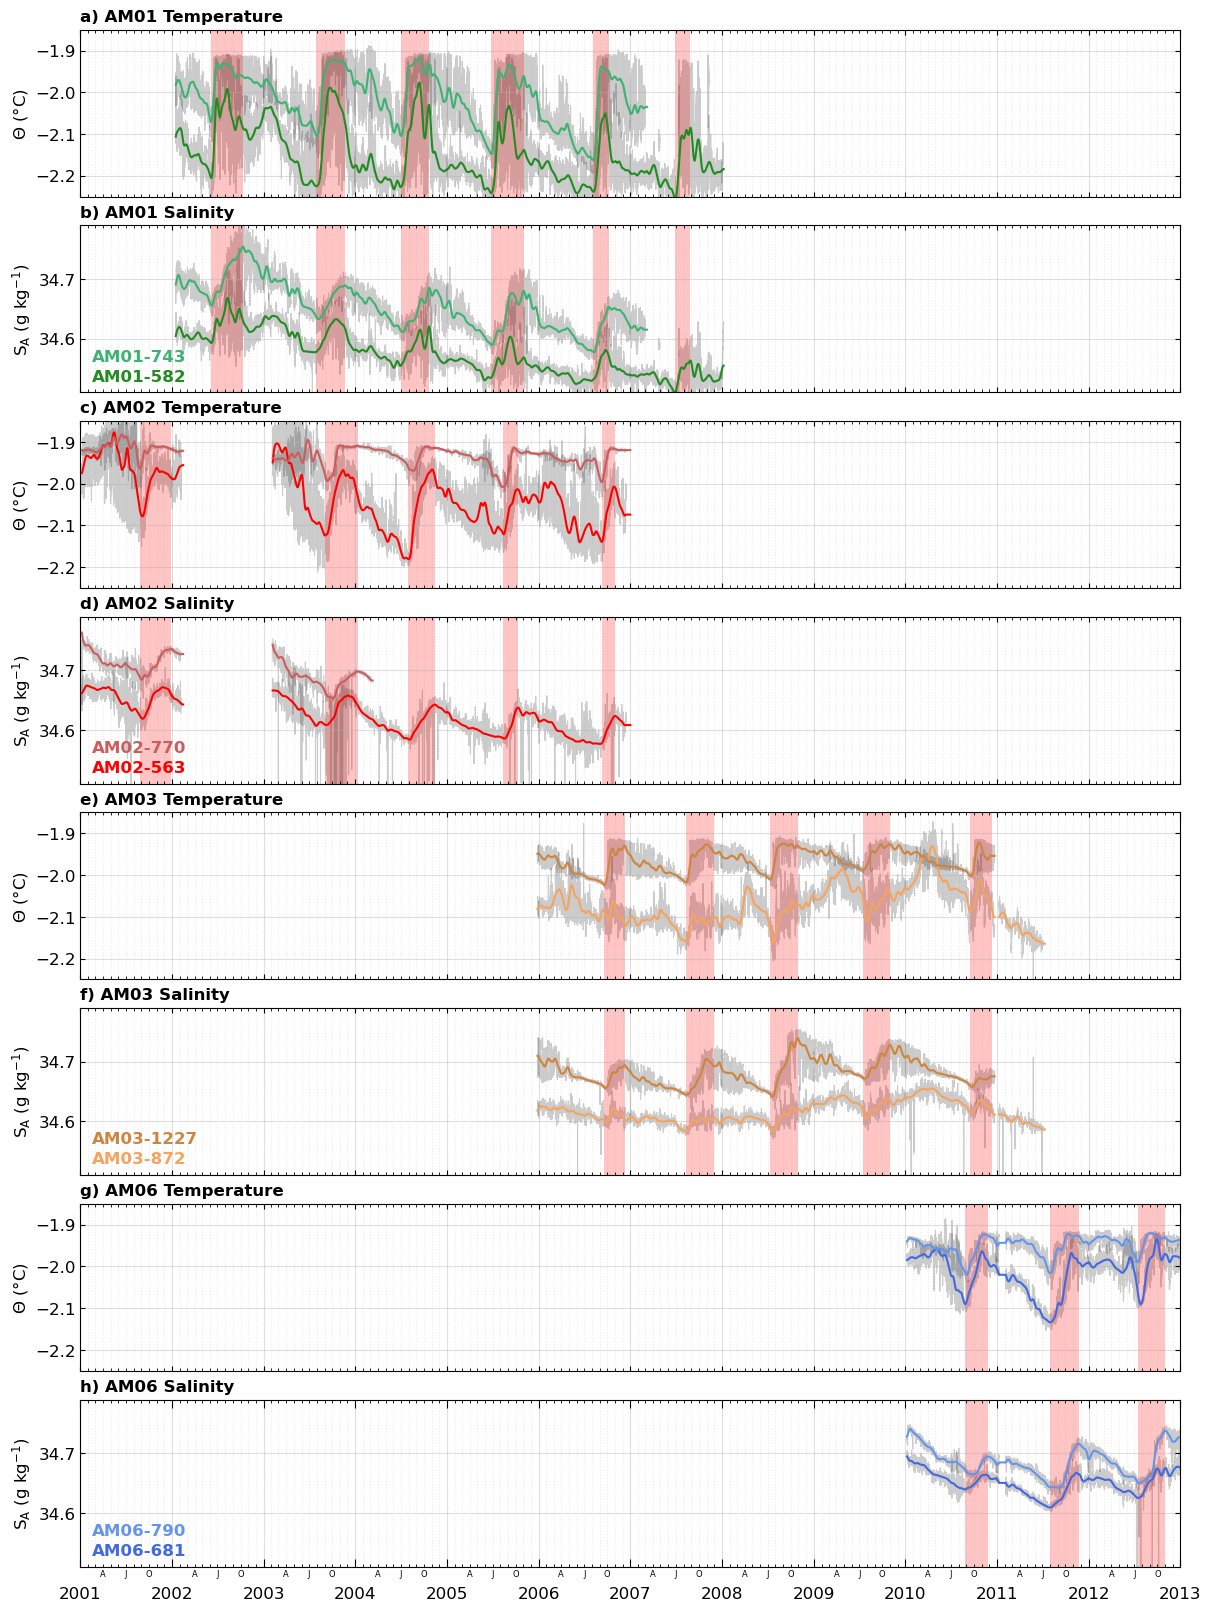

In [14]:
# Define the limits of the y-axes for plots of temperature and salinity
ylim_temp = (-2.25, -1.85)
ylim_sal = (34.5, 34.8)

# >>> NEW: bottom two MicroCATs at each borehole used for the HSSW analysis (borehole, cat)
boreholes = [
    ("AM01", "1970"), ("AM01", "1971"),
    ("AM02", "1624"), ("AM02", "1174"),
    ("AM03", "4054"), ("AM03", "3883"),
    ("AM06", "7324"), ("AM06", "7323"),
]
fig, axes = plt.subplots(8, 1, sharex=True, figsize=(12, 16), layout='constrained')

# Panel labels run left to right, then down
panel_labels = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l']
panel_count = 0

all_years = []

for i, (bh, cat) in enumerate(boreholes):
    # Instruments come in pairs per borehole, so i // 2 gives the borehole's position and picks its two rows
    axT, axS = axes[2 * (i // 2)], axes[2 * (i // 2) + 1]

    r = composite_seasonal_cycle(df, bh, cat)
    sub = r["data"]
    label = f"{bh}-{AVG_PRESSURES[cat]:.0f}"

    # Extract day of year and year from the time column
    sub["year"] = sub["time"].dt.year

    years = [2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012]
    all_years += years

    # Retrieve the position of the iterated MicroCAT in the water column
    position = sub["water_column_position"].iloc[0]

    # Plot each individual year
    for year in years:
        first = year == years[0]

        # Filter the subset for the current year
        year_data = sub[sub["year"] == year]

        # Plot raw data
        axT.plot(year_data["time"], year_data["conservative_temperature"], color='black', label="_", **raw_kw)
        axS.plot(year_data["time"], year_data["absolute_salinity"], color='black', label="_", **raw_kw)

        # Plot smoothed data
        axT.plot(year_data["time"], year_data["conservative_temperature_smooth_30d"], label=label if first else "_", color=BOREHOLE_COLOURS[bh][cat], **smooth_kw)
        axS.plot(year_data["time"], year_data["absolute_salinity_smooth_30d"], label=label if first else "_", color=BOREHOLE_COLOURS[bh][cat], **smooth_kw)

    axS.text(0.01, 0.05 + 0.12 * (i % 2), label, transform=axS.transAxes, fontweight='bold', color=BOREHOLE_COLOURS[bh][cat], va="bottom", ha="left", zorder=2)

    if i % 2 == 0:
        axT.set_title(f'{panel_labels[panel_count]}) {bh} Temperature', loc='left', fontweight="bold")
        panel_count += 1
        axS.set_title(f'{panel_labels[panel_count]}) {bh} Salinity', loc='left', fontweight="bold")
        panel_count += 1

# --------------- BOREHOLE HSSW DURATION BANDS ---------------
for i, (bh, cat) in enumerate(boreholes):
    axT, axS = axes[2 * (i // 2)], axes[2 * (i // 2) + 1]

    events = borehole_summary[borehole_summary["borehole"] == bh]

    for _, event in events.iterrows():
        if pd.isna(event["arrival_time"]) or pd.isna(event["salt_peak_time"]):
            continue

        for ax in (axT, axS):
            ax.axvspan(event["arrival_time"], event["salt_peak_time"], color="red", alpha=0.12, zorder=1, linewidth=0)

y0, y1 = min(all_years), max(all_years) + 1
# Add years as major ticks
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[-1].set_xlim(pd.Timestamp(f"{y0}-01-01"), pd.Timestamp(f"{y1}-01-01"))
# Add months as minor ticks
axes[-1].xaxis.set_minor_locator(mdates.MonthLocator())
axes[-1].xaxis.set_minor_formatter(mticker.FuncFormatter(lambda x, pos: (lambda d: d.strftime("%b")[0] if d.month in {4, 7, 10} else "")(mdates.num2date(x))))

for ax in axes:
    ax.tick_params(axis="both", which="both", direction="in", top=True, right=True)
    ax.grid(True, which="major", linestyle="-", alpha=0.4)
    ax.grid(True, which="minor", linestyle=":", alpha=0.25)

axes[-1].tick_params(axis="x", which="minor", labelsize=6, pad=2)
axes[-1].tick_params(axis="x", which="major", pad=14, length=6)

for row in range(4):
    # Set the axis limits
    axes[2 * row].set_ylim(ylim_temp[0], ylim_temp[1])
    # Inset the salinity limits so ticks don't sit on the frame
    axes[2 * row + 1].set_ylim(ylim_sal[0] + 0.01, ylim_sal[1] - 0.01)
    # Fixed 0.1 interval on temperature, as in the composite figure
    axes[2 * row].yaxis.set_major_locator(mticker.MultipleLocator(0.1))
    # Label the y-axis
    axes[2 * row].set_ylabel(r"$\Theta$ (°C)")
    axes[2 * row + 1].set_ylabel(r"$\mathrm{S_{A} \ (g \ kg^{-1}})$")

fig.savefig('/g/data/gv90/ad6790/amery-amisor/notebooks/figures/ObsTimeSeriesHSSW_CompleteRecord.png', format='png', dpi=600)
plt.show()